# LOCAL OUTLIER FACTOR (LOF)

LEVEL: 🟡 MEDIUM

Goal:

```text
Understand LOF internally + use sklearn.
```

We will NOT implement LOF from scratch.

## What's in this notebook

- 1\. Why LOF?
- 2\. Main idea
- 3\. Why local density?
- 4\. Internal working
- 5\. Step 1 — k nearest neighbors
- 6\. Step 2 — k-distance
- 7\. Step 3 — reachability distance
- 8\. Step 4 — local reachability density
- 9\. Step 5 — LOF score
- 10\. Small numerical example
- 11\. Important parameters
- 15\. Train LOF
- 17\. Get LOF scores
- 18\. Find most anomalous points
- 19\. Important — novelty=False vs novelty=True
- 20\. LOF for new unseen data
- 22\. Score new data
- 23\. score_samples
- 24\. Feature scaling
- 25\. High-dimensional data
- 26\. LOF vs isolation forest
- 27\. LOF vs DBSCAN
- 28\. LOF vs KNN
- 29\. LOF vs one-class SVM
- 30\. Advantages
- 31\. Limitations
- 32\. Interview questions
- 33\. 30-second interview answer
- 34\. Working tree
- 35\. Final mental model

# 1. WHY LOF?

LOF = Local Outlier Factor

It is an UNSUPERVISED anomaly detection algorithm.

Main question:

```text
"Is this point much less dense than its neighbors?"
```

Example:

```text
 ● ● ● ●
● ● ● ● ●
 ● ● ● ●
```

This is a dense region.

```text
X
```

X is far away from the nearby points.

Its local density is much lower.

Therefore:

```text
X → possible anomaly
```

# 2. MAIN IDEA

LOF does NOT simply ask:

```text
"Is this point far from the entire dataset?"
```

Instead it asks:

```text
"How dense is this point compared with
 the density around its neighbors?"
```

This is why LOF is called:

```text
LOCAL Outlier Factor
```

Important:

```text
Isolation Forest
    → isolation/path length

LOF
    → local density
```

# 3. WHY LOCAL DENSITY?

Consider two clusters:

Dense cluster:

```text
 ● ● ● ●
● ● ● ● ●
 ● ● ● ●
```

Sparse cluster:

```text
   ●     ●
      ●
●          ●
```

A point in the sparse cluster may have lower density  
than points in the dense cluster.

But that does NOT automatically make it an anomaly.

It should be compared with its LOCAL neighbors.

If:

```text
density(point) ≈ density(neighbors)

    → probably normal
```

If:

```text
density(point) << density(neighbors)

    → potential anomaly
```

# 4. INTERNAL WORKING

For every point P:

```text
STEP 1
    Find its k nearest neighbors.

STEP 2
    Calculate k-distance.

STEP 3
    Calculate reachability distance.

STEP 4
    Calculate local reachability density.

STEP 5
    Compare P's density with neighbor densities.

STEP 6
    Calculate LOF score.
```

Overall:

```text
       Point P
          |
          v
   Find k nearest neighbors
          |
          v
      k-distance
          |
          v
 Reachability distances
          |
          v
Local reachability density
          |
          v
Compare with neighbors
          |
          v
      LOF score
```

# 5. STEP 1 — k NEAREST NEIGHBORS

Choose:

```text
k = n_neighbors
```

Example:

```text
k = 5
```

For every point, find its 5 nearest neighbors.

Small k:

```text
very local
can detect small/local anomalies
more sensitive to noise
```

Large k:

```text
broader neighborhood
smoother
may miss very local anomalies
```

IMPORTANT PARAMETER:

```text
n_neighbors
```

# 6. STEP 2 — k-DISTANCE

Suppose:

```text
k = 3
```

For point P:

```text
1st nearest neighbor = distance 2
2nd nearest neighbor = distance 3
3rd nearest neighbor = distance 5
```

Therefore:

```text
k-distance(P) = 5
```

This gives us a measure of the local scale around P.

# 7. STEP 3 — REACHABILITY DISTANCE

LOF uses:

```text
reachability distance
```

Formula:

reach-dist_k(P, O)

```text
= max(
      k-distance(O),
      distance(P, O)
  )
```

where:

```text
P = current point
O = neighboring point
```

Why?

It prevents very small distances in extremely dense  
regions from making density calculations unstable.

# 8. STEP 4 — LOCAL REACHABILITY DENSITY

Local reachability density:

```text
                                k
LRD(P) = ----------------------------------------------
          sum of reach-dist(P, O) over the k neighbours O
```

i.e. LRD = 1 / (average reachability distance to the k neighbours).

In simple words:

```text
LRD ≈ inverse of average reachability distance
```

Therefore:

```text
small distances
     ↓
high density


large distances
     ↓
low density
```

# 9. STEP 5 — LOF SCORE

LOF compares:

```text
neighbor density
```

against:

```text
point density
```

Simplified:

```text
                 average LRD of neighbors
LOF(P) ≈ -----------------------------------
                      LRD(P)
```

Therefore:

```text
LOF ≈ 1
    → similar density to neighbors
    → probably normal


LOF > 1
    → lower density than neighbors
    → possible anomaly


LOF >> 1
    → much lower density
    → stronger anomaly signal
```

# 10. SMALL NUMERICAL EXAMPLE

Suppose:

```text
LRD(P) = 0.20
```

Neighbor densities:

```text
0.80
0.90
0.70
0.80
```

Average neighbor density:

```text
(0.80 + 0.90 + 0.70 + 0.80) / 4

= 0.80
```

LOF:

```text
0.80 / 0.20

= 4
```

LOF ≈ 4

This means P is much less dense than its neighbors.

Therefore P is a strong anomaly candidate.

# 11. IMPORTANT PARAMETERS

n_neighbors:

```text
Size of local neighborhood.

Most important parameter.
```

contamination:

```text
Expected proportion of outliers.

Example:

    contamination=0.05

approximately 5% are expected to be anomalies.
```

metric:

```text
Distance metric.

Examples:

    "euclidean"
    "manhattan"
    "minkowski"
    "cosine"
```

novelty:

```text
False:
    Detect outliers in the training dataset.

True:
    Allows scoring/predicting NEW unseen observations.
```

n_jobs:

```text
Number of CPU workers for neighbor search.
```

leaf_size:

```text
Controls tree-based nearest-neighbor search.
```

# 12. INSTALLATION

sklearn is normally already available.

If needed:

%pip install scikit-learn

# 13. IMPORTS

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import LocalOutlierFactor

# 14. CREATE SIMPLE DATASET

Normal observations:

Dense cluster around (0, 0)

In [2]:
rng = np.random.RandomState(42)

X_normal = 0.5 * rng.randn(300, 2)

Anomalies:

Far away from the normal cluster.

In [3]:
X_anomaly = rng.uniform(
    low=4,
    high=6,
    size=(15, 2)
)


# Combine them.
#
X = np.vstack([
    X_normal,
    X_anomaly
])

print("Dataset shape:", X.shape)

Dataset shape: (315, 2)


# 15. TRAIN LOF

n_neighbors:

```text
Examine approximately 20 nearby points.
```

contamination:

```text
Expect around 5% anomalies.
```

metric:

```text
Euclidean distance.
```

n_jobs:

```text
Use all available CPU cores.
```

In [4]:
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    metric="euclidean",
    n_jobs=-1
)

fit_predict:

```text
Fits LOF and immediately returns:

+1 → normal
-1 → anomaly
```

In [5]:
predictions = lof.fit_predict(X)


print("Unique predictions:", np.unique(predictions))

print(
    "Number of anomalies:",
    np.sum(predictions == -1)
)

Unique predictions: [-1  1]
Number of anomalies: 16


# 16. VISUALIZE

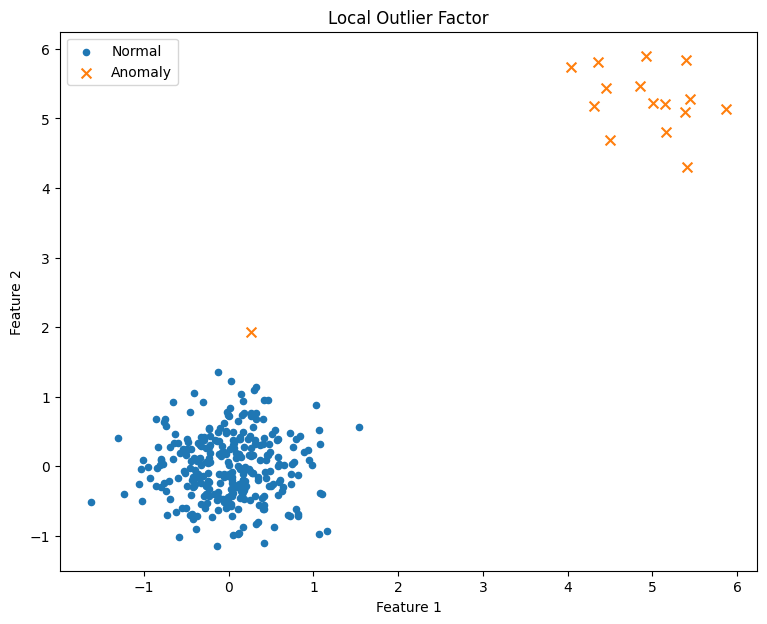

In [6]:
plt.figure(figsize=(9, 7))

# Normal points
plt.scatter(
    X[predictions == 1, 0],
    X[predictions == 1, 1],
    label="Normal",
    s=20
)

# Anomalies
plt.scatter(
    X[predictions == -1, 0],
    X[predictions == -1, 1],
    label="Anomaly",
    s=50,
    marker="x"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Local Outlier Factor")
plt.legend()

plt.show()

# 17. GET LOF SCORES

sklearn exposes:

```text
negative_outlier_factor_
```

Important:

sklearn stores the score with the opposite sign from  
the intuitive positive LOF interpretation.

Therefore:

```text
intuitive_LOF ≈ -negative_outlier_factor_
```

Higher intuitive LOF:

```text
more anomalous
```

In [7]:
lof_scores = -lof.negative_outlier_factor_

print("First 10 LOF scores:")
print(lof_scores[:10])

First 10 LOF scores:
[1.01258267 1.08480434 1.0444919  1.17359132 0.98541586 0.99737444
 1.45917586 1.20604646 1.00105675 1.24727575]


# 18. FIND MOST ANOMALOUS POINTS

In [8]:
# Higher LOF = more anomalous.
#
most_anomalous_indices = np.argsort(
    lof_scores
)[-10:][::-1]


print("Most anomalous points:")

print(
    X[most_anomalous_indices]
)


print("Their LOF scores:")

print(
    lof_scores[most_anomalous_indices]
)

Most anomalous points:
[[4.36319543 5.81690112]
 [5.39330165 5.84499876]
 [4.03622037 5.74424782]
 [4.92401161 5.89456668]
 [5.44007307 5.28229527]
 [5.86423656 5.13026637]
 [5.38789689 5.08544889]
 [5.15257672 5.21343009]
 [4.84826134 5.47288847]
 [5.01177736 5.22290847]]
Their LOF scores:
[3.8478133  3.84293132 3.80794672 3.8011592  3.78756814 3.77615521
 3.76149089 3.74870094 3.74514915 3.73453639]


# 19. IMPORTANT — novelty=False vs novelty=True

By default:

```text
novelty=False
```

This is mainly for detecting outliers in the dataset  
used during fit.

Example:

```text
predictions = lof.fit_predict(X)
```

If you want to fit on training data and later detect  
anomalies in NEW unseen data:

```text
novelty=True
```

# 20. LOF FOR NEW UNSEEN DATA

In [9]:
lof_new = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    metric="euclidean",
    novelty=True,
    n_jobs=-1
)


# In practice, fit a novelty model ONLY on clean, normal data.
# Here X still contains the anomalies, to keep the example short.
lof_new.fit(X)

,n_neighbors,20
,algorithm,'auto'
,leaf_size,30
,metric,'euclidean'
,p,2
,metric_params,None
,contamination,0.05
,novelty,True
,n_jobs,-1


# 21. CREATE NEW OBSERVATIONS

In [10]:
new_points = np.array([
    [0.1, 0.2],     # likely normal
    [0.5, -0.2],    # likely normal
    [4.5, 4.5],     # likely anomaly
    [5.5, 5.0]      # likely anomaly
])

Predict:

```text
+1 → normal
-1 → anomaly
```

In [11]:
new_predictions = lof_new.predict(new_points)

print("New predictions:")
print(new_predictions)

New predictions:
[ 1  1 -1 -1]


# 22. SCORE NEW DATA

decision_function:

```text
positive → more normal
negative → more anomalous
```

In [12]:
decision_scores = lof_new.decision_function(
    new_points
)

print("Decision scores:")
print(decision_scores)

Decision scores:
[ 1.40115737  1.33637459 -0.5851256  -0.6749288 ]


# 23. SCORE_SAMPLES

score_samples gives an anomaly-related score.

Lower / more negative:

```text
more abnormal
```

In [13]:
sample_scores = lof_new.score_samples(
    new_points
)

print("Sample scores:")
print(sample_scores)

Sample scores:
[-0.98562437 -1.05040715 -2.97190735 -3.06171055]


# 24. FEATURE SCALING

LOF depends on distances.

Therefore, feature scale matters.

Example:

```text
age       → 20 to 60
salary    → 20,000 to 2,000,000
```

Salary can dominate Euclidean distance.

In such cases use StandardScaler.

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# Train LOF on scaled data.
#
lof_scaled = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    metric="euclidean",
    n_jobs=-1
)

pred_scaled = lof_scaled.fit_predict(
    X_scaled
)

print(
    "Anomalies after scaling:",
    np.sum(pred_scaled == -1)
)

Anomalies after scaling: 16


# 25. HIGH-DIMENSIONAL DATA

LOF relies heavily on distances.

In very high dimensions:

```text
distances become less informative.
```

This is called the:

```text
Curse of Dimensionality
```

Possible approach:

```text
High-dimensional X
      |
      v
     PCA
      |
      v
Lower-dimensional X
      |
      v
     LOF
```

But this should be validated for the specific problem.

# 26. LOF vs ISOLATION FOREST

Isolation Forest:

```text
Main question:

    "How quickly can I isolate this point?"
```

Mechanism:

```text
Random trees
```

Signal:

```text
Path length
```

LOF:

```text
Main question:

    "Is this point much less dense than its neighbors?"
```

Mechanism:

```text
Nearest neighbors
```

Signal:

```text
Relative local density
```

# 27. LOF vs DBSCAN

DBSCAN:

```text
Finds dense clusters.

Main parameters:

    eps
    min_samples
```

LOF:

```text
Measures whether a point has unusually low local density.

Main parameter:

    n_neighbors
```

DBSCAN asks:

```text
"Is this point part of a dense region?"
```

LOF asks:

```text
"Is this point less dense than its neighbors?"
```

# 28. LOF vs KNN

Both use nearest neighbors.

KNN:

```text
Usually supervised.

Uses labels to make predictions.
```

LOF:

```text
Unsupervised.

Uses distances to estimate local density.
```

KNN:

```text
"What do my neighbors tell me?"
```

LOF:

```text
"How does my density compare with my neighbors?"
```

# 29. LOF vs ONE-CLASS SVM

LOF:

```text
Neighbor/density based.
```

One-Class SVM:

```text
Learns a boundary around normal observations.
```

LOF:

```text
Local view.
```

One-Class SVM:

```text
Boundary-based view.
```

# 30. ADVANTAGES

1. Detects local anomalies.

2. Does not require anomaly labels.

```text
3. Can handle different local densities better than
   purely global methods.
```

4. Supports different distance metrics.

5. Easy to use with sklearn.

# 31. LIMITATIONS

1. Can be computationally expensive on large datasets.

2. Sensitive to n_neighbors.

3. Sensitive to distance metric.

4. High-dimensional data can make distances less useful.

5. Feature scaling can strongly affect results.

6. contamination/threshold selection can be difficult.

IMPORTANT FOR YOUR ML ENGINEERING WORK:

For very large datasets, don't blindly run LOF on  
hundreds of thousands/millions of high-dimensional rows.

Isolation Forest is often a more practical first choice.

# 32. INTERVIEW QUESTIONS

Q1. What is LOF?

Answer:

LOF is an unsupervised, density-based anomaly detection  
algorithm that compares the local density of a point  
with the density of its nearest neighbors.

Q2. Why is it called Local Outlier Factor?

Answer:

Because it measures how much a point's local density  
differs from the density of its local neighborhood.

Q3. What does LOF ≈ 1 mean?

Answer:

The point has approximately the same density as its  
neighbors and is generally considered normal.

Q4. What does LOF > 1 mean?

Answer:

The point is less dense than its neighbors and may be  
an outlier. Larger values indicate a stronger anomaly  
signal.

Q5. What is n_neighbors?

Answer:

It controls the size of the local neighborhood used  
to estimate density.

Q6. Why is scaling important?

Answer:

LOF is distance-based, so features with larger numerical  
scales can dominate the distance calculation.

Q7. LOF vs Isolation Forest?

Answer:

Isolation Forest uses random tree partitions and  
isolation path length, whereas LOF uses nearest  
neighbors and relative local density.

Q8. What is novelty=True?

Answer:

It allows the fitted LOF model to score and predict  
anomalies for new unseen observations.

# 33. 30-SECOND INTERVIEW ANSWER

"LOF is an unsupervised density-based anomaly detection  
algorithm. It finds the nearest neighbors of each point,  
estimates its local reachability density, and compares that  
density with the densities of its neighbors. If a point is  
significantly less dense than its neighborhood, its LOF  
score becomes larger and it is considered a potential  
anomaly. The most important parameter is n_neighbors because  
it determines the size of the local neighborhood."

# 34. WORKING TREE

```text
                INPUT DATA
                    |
                    v
           Choose n_neighbors
                    |
                    v
         Find nearest neighbors
                    |
                    v
              k-distance
                    |
                    v
       Reachability distance
                    |
                    v
   Local Reachability Density
                    |
                    v
Compare point density with neighbors
                    |
                    v
               LOF score
                    |
         -------------------
         |                 |
         v                 v
      ≈ 1              >> 1
         |                 |
         v                 v
      NORMAL            ANOMALY
```

# 35. FINAL MENTAL MODEL

Isolation Forest:

```text
"How quickly can I isolate this point?"
```

LOF:

```text
"Is this point much less dense than the points
 around it?"
```

DBSCAN:

```text
"Is this point part of a dense region?"
```

KNN:

```text
"What do my nearest neighbors tell me?"
```

# END OF LOF